# Shift-and-Stack: primeira execução

Experimento controlado com ruído gaussiano, estrelas e um objeto fraco em movimento
linear. **Não são dados SPHEREx.** A busca não recebe a trajetória injetada.

Base: Wang, Zhao e Li (2018), [artigo](https://doi.org/10.1016/j.chinastron.2018.09.007),
seções 3.2.2, 3.2.3 e 4.3. O refinamento por ajuste de PSF é uma adaptação,
não uma reprodução do critério de alongamento do artigo.

In [1]:
from pathlib import Path

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
print("Projeto:", ROOT)

Projeto: /home/tatiana/Transferências/projetos/nasaSpaceApps


In [2]:
import json

from spherex_tracking.demo import run_demo

OUTPUT = ROOT / "outputs" / "demo"
report_path = OUTPUT / "report.json"
if report_path.exists():
    report = json.loads(report_path.read_text())
else:
    report = run_demo(OUTPUT, seed=42, null_trials=8)

# Para refazer a experiência: report = run_demo(OUTPUT, seed=42, null_trials=8)
for key in [
    "n_exposures",
    "expected_single_frame_snr_median",
    "best_candidate",
    "position_error_pixels",
    "velocity_error_pixels_per_hour",
    "null_maximum_snrs",
    "recovered_within_tolerance",
]:
    print(f"{key}: {report[key]}")

n_exposures: 32
expected_single_frame_snr_median: 2.2000779694248047
best_candidate: {'x': 30.40199476292732, 'y': 31.70195309571455, 'vx': 5.624658381083599, 'vy': -2.6049645661520273, 'snr': 12.384718060859448, 'flux': 9.112657984862246, 'n_frames': 32}
position_error_pixels: 0.1414783626727431
velocity_error_pixels_per_hour: 0.338282127956083
null_maximum_snrs: [3.2231725148870605, 3.709935392301918, 2.9985323253306486, 3.115266237327541, 3.6279409596505627, 3.619673582075858, 3.7656537909217263, 3.0978136732324018]
recovered_within_tolerance: True


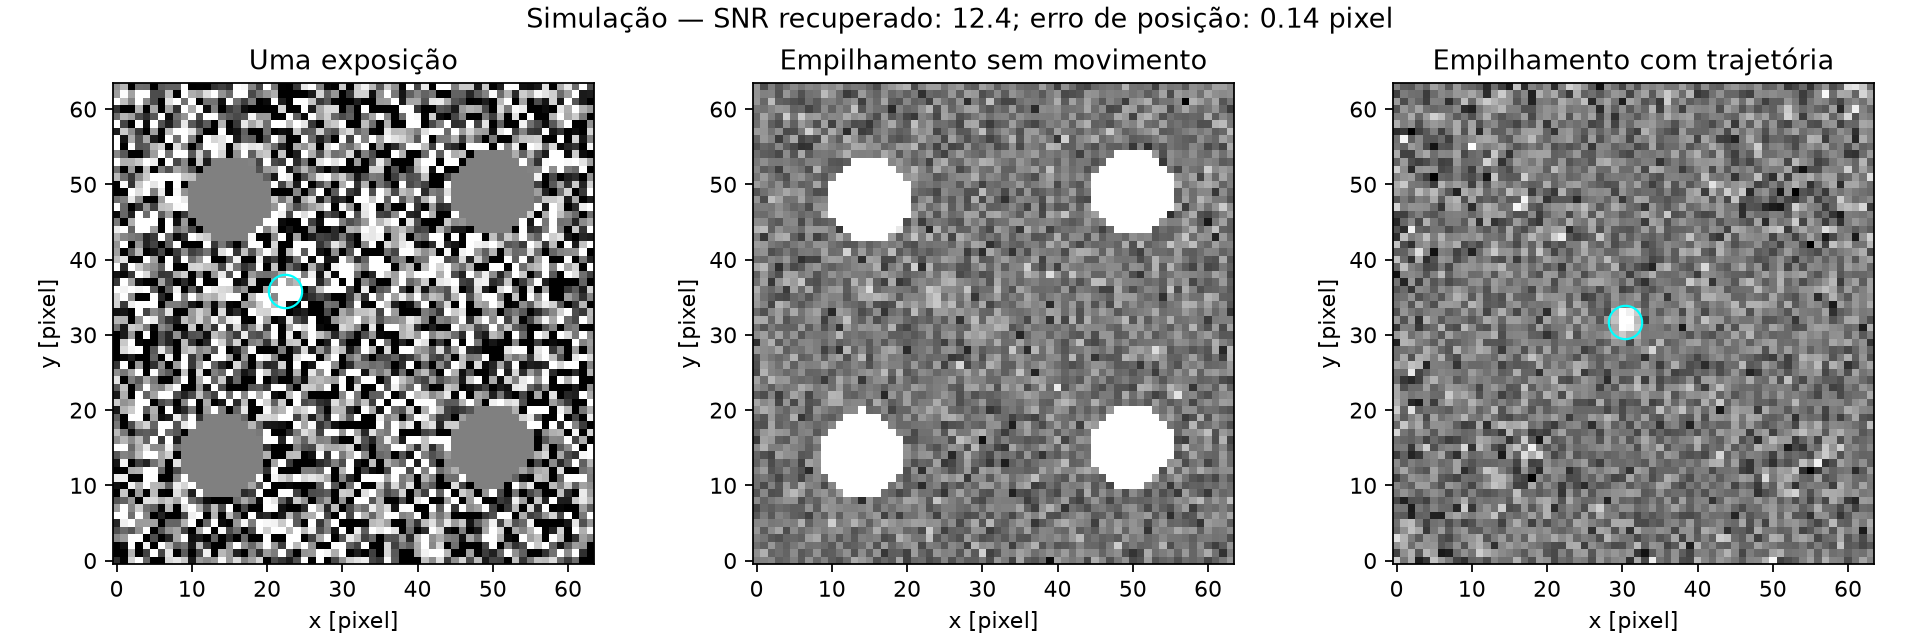

In [3]:
from IPython.display import Image, display

display(Image(filename=str(OUTPUT / "comparison.png")))

In [4]:
import numpy as np

from spherex_tracking.core import prepare, refine, search
from spherex_tracking.simulation import simulate

# Execute esta célula para modificar a grade ou os parâmetros da busca.
simulation = simulate(seed=42)
sequence = prepare(simulation.sequence)
coarse = search(sequence, np.arange(-8, 9), np.arange(-5, 6), threshold=5, max_candidates=3)
candidates = sorted(
    [refine(sequence, c, velocity_radius=1) for c in coarse], key=lambda c: c.snr, reverse=True
)
candidates

[Candidate(x=30.40199476292732, y=31.70195309571455, vx=5.624658381083599, vy=-2.6049645661520273, snr=12.384718060859448, flux=9.112657984862246, n_frames=32),
 Candidate(x=30.401951352368982, y=31.702015184124587, vx=5.624638052523556, vy=-2.605000840345076, snr=12.384718058175526, flux=9.11265798387469, n_frames=32),
 Candidate(x=30.41667575055933, y=31.602388626554184, vx=5.564419235420228, vy=-3.0000000000000195, snr=12.062066880938387, flux=8.875251896499803, n_frames=32)]

## Como interpretar

A posição é definida na mediana das épocas, `x` é coluna, `y` é linha, e a
velocidade está em pixels/hora. O SNR vem do ajuste ponderado da PSF nos pixels
originais; a imagem de demonstração usa deslocamentos arredondados.

As medições individuais do relatório são fotometria forçada na trajetória
verdadeira para validação. Não representam detecção cega por exposição.
Os controles repetem a mesma busca e refinamento sem injetar objeto móvel.
Oito controles e uma única injeção não estabelecem significância global,
completude ou pureza. Veja os limites em `README.md`.